# 04 · The unscented Kalman filter

The EKF approximates the *function* (by a tangent plane) and propagates the Gaussian exactly
through the approximation. The UKF does the opposite: it keeps the *function* exact and
approximates the *distribution* by a handful of deterministically chosen points, the
**sigma points**. Then it fits a Gaussian to where those points land (Julier & Uhlmann, 1997).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import (World, simulate, EKF, UKF, run_filter, motion_model, motion_jacobians,
                            merwe_weights, sigma_points, unscented_transform, position_error, nees,
                            nees_bounds, position_rmse)
from bayesian_filters.ukf import pose_mean, pose_residual
from bayesian_filters import viz
viz.style()

## 1. The unscented transform

Let $x \sim (m, P)$ in $\mathbb R^n$ and $y = g(x)$. Choose $2n+1$ points
$$
\chi_0 = m,\qquad \chi_{\pm i} = m \pm \big(\sqrt{(n+\lambda)P}\big)_i,\quad i = 1..n,
$$
where $(\sqrt A)_i$ is the $i$-th column of a matrix square root ($A = LL^\top$, Cholesky), and
weights
$$
W^{(m)}_0 = \frac{\lambda}{n+\lambda},\quad W^{(c)}_0 = \frac{\lambda}{n+\lambda} + 1 - \alpha^2 + \beta,\quad
W^{(m)}_{\pm i} = W^{(c)}_{\pm i} = \frac{1}{2(n+\lambda)},\qquad \lambda = \alpha^2(n+\kappa) - n .
$$
By construction the weighted points have **exactly** mean $m$ and covariance $P$ (the $\pm$
pairs cancel in the mean, and $\sum_i \frac{1}{2(n+\lambda)} \cdot 2(n+\lambda) L_i L_i^\top = P$).
Then
$$
\bar y = \sum_j W^{(m)}_j\, g(\chi_j),\qquad P_y = \sum_j W^{(c)}_j\,\big(g(\chi_j) - \bar y\big)\big(g(\chi_j)-\bar y\big)^\top .
$$
A Taylor expansion of $g$ around $m$ shows that $\bar y$ is correct up to **second order**: the
term $\tfrac12 \operatorname{tr}(\nabla^2 g\, P)$ that the EKF drops is captured. $P_y$ is correct
to first order, like the EKF, but with some of the higher-order terms. No Jacobian is needed.

* $\alpha$ sets the spread of the points and $\kappa$ is a secondary scaling. $\beta = 2$ is
  optimal for Gaussian priors (it adds the 4th-moment information to $W_0^{(c)}$).
* We use $\alpha = 1, \beta = 2, \kappa = 0$, so $\lambda = 0$ and $W^{(m)}_0 = 0$. The classical
  choice $\lambda = 3 - n$ makes $W_0$ **negative** as soon as $n > 3$, and then $P_y$ is no
  longer guaranteed to be positive semi-definite.

**Back to the arc of notebook 03:**

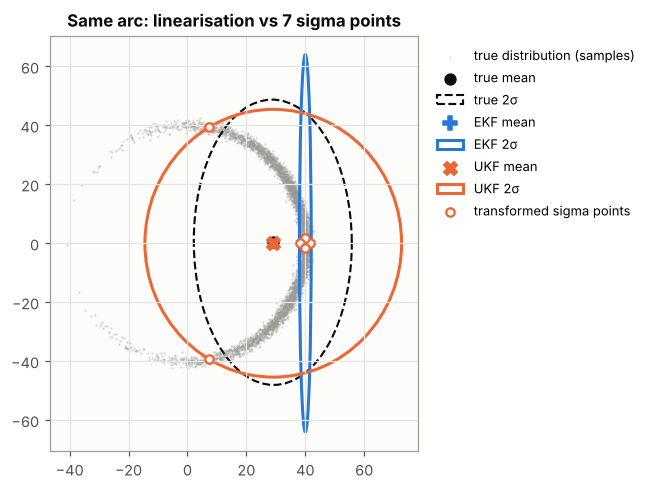

EKF: mean error 11.05
UKF: mean error  0.36


In [2]:
rng = np.random.default_rng(0)
m0, P0 = np.zeros(3), np.diag([1.0, 1.0, 0.8**2])
u = np.array([4.0, 0.0])
def g(X):
    """10 noise-free steps of 4 units straight ahead."""
    for _ in range(10):
        X = motion_model(X, u)
    return X

samples = g(rng.multivariate_normal(m0, P0, 5000))
# EKF
m_e, P_e = m0.copy(), P0.copy()
for _ in range(10):
    F, _ = motion_jacobians(m_e, u)
    m_e, P_e = motion_model(m_e, u), F @ P_e @ F.T
# UT
lam, Wm, Wc = merwe_weights(3)
chi = sigma_points(m0, P0, lam)
m_u, P_u, _ = unscented_transform(g(chi), Wm, Wc, pose_mean, pose_residual)

fig, ax = plt.subplots(figsize=(6.6, 4.9))
ax.scatter(samples[:, 0], samples[:, 1], s=2, color=viz.MUTED, alpha=0.4, lw=0, label="true distribution (samples)")
mc_m, mc_P = samples[:, :2].mean(0), np.cov(samples[:, :2].T)
ax.scatter(*mc_m, s=50, c=viz.INK, label="true mean", zorder=6)
viz.cov_ellipse(ax, mc_m, mc_P, ec=viz.INK, ls="--", label="true 2σ")
ax.scatter(*m_e[:2], marker="P", s=80, c=viz.COLORS["EKF"], zorder=6, label="EKF mean")
viz.cov_ellipse(ax, m_e, P_e, name="EKF", lw=2, label="EKF 2σ")
ax.scatter(*m_u[:2], marker="X", s=80, c=viz.COLORS["UKF"], zorder=6, label="UKF mean")
viz.cov_ellipse(ax, m_u, P_u, name="UKF", lw=2, label="UKF 2σ")
ax.scatter(*g(chi)[:, :2].T, marker="o", s=30, fc="white", ec=viz.COLORS["UKF"], lw=1.5, zorder=7, label="transformed sigma points")
ax.set_aspect("equal"); ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8.5)
ax.set_title("Same arc: linearisation vs 7 sigma points")
plt.show()
for name, mm in [("EKF", m_e), ("UKF", m_u)]:
    print(f"{name}: mean error {np.hypot(*(mm[:2] - mc_m)):5.2f}")

The sample mean of 5000 draws is itself noisy. The exact answer is known: the heading error
$e\sim\mathcal N(0,0.8^2)$ is the same for the ten steps, so the robot ends $40$ units away in the direction
$e$, and with $\mathbb E[\cos e]=e^{-\sigma^2/2}$ and the variances of $\cos e$ and $\sin e$
(Exercises 1.2 and 4.2) the exact mean and standard deviations follow:

In [3]:
s2 = 0.8**2
exact_mean = np.array([40 * np.exp(-s2 / 2), 0.0])
exact_sd = np.sqrt([1 + 1600 * 0.5 * (1 - np.exp(-s2)) ** 2,   # along: 40 cos e (+ start variance 1)
                    1 + 1600 * 0.5 * (1 - np.exp(-2 * s2))])    # across: 40 sin e (+ start variance 1)
print(f"exact mean ({exact_mean[0]:.2f}, 0):  EKF {np.hypot(*(m_e[:2] - exact_mean)):.2f} away,  "
      f"UKF {np.hypot(*(m_u[:2] - exact_mean)):.2f} away")
print(f"standard deviation along / across:  exact {exact_sd[0]:.1f} / {exact_sd[1]:.1f},  "
      f"UKF {np.sqrt(P_u[0, 0]):.1f} / {np.sqrt(P_u[1, 1]):.1f}")

exact mean (29.05, 0):  EKF 10.95 away,  UKF 0.08 away
standard deviation along / across:  exact 13.4 / 24.1,  UKF 21.8 / 22.7


Seven function evaluations put the UKF's mean almost on the true mean, and its ellipse covers
the arc. It is somewhat too wide across the direction of travel, but nowhere near the
EKF's needle, whose mean sits 11 units ahead at the tip of the arc. Neither filter can
represent the *arc* itself: both summarise it as a Gaussian. Representing the arc takes
particles (notebook 05).

## 2. The UKF for the mower

**Non-additive motion noise.** The control noise is turned before it is driven, so it cannot
simply be added as a $Q$. The standard trick is to **augment** the state with the noise:
$$
x^a = \begin{pmatrix} x\\ \varepsilon\end{pmatrix} \sim \mathcal N\!\left(\begin{pmatrix}\hat x\\ 0\end{pmatrix},
\begin{pmatrix}P & 0\\0 & M\end{pmatrix}\right),\qquad n_a = 3 + 2 = 5,
$$
draw $2n_a+1 = 11$ sigma points, and push each through $f(x, u + \varepsilon)$.

**Update.** Draw $2\cdot 3+1 = 7$ fresh sigma points from the predicted $(\bar x, \bar P)$, map them
through $h$, and compute
$$
\hat z = \sum_j W^{(m)}_j Z_j,\quad S = \sum_j W^{(c)}_j (Z_j - \hat z)(Z_j-\hat z)^\top + R,\quad
P_{xz} = \sum_j W^{(c)}_j (\chi_j - \bar x)(Z_j - \hat z)^\top,
$$
$$
K = P_{xz} S^{-1},\qquad \hat x = \bar x + K(z - \hat z),\qquad P = \bar P - K S K^\top .
$$
This is the Kalman update with $P_{xz}$ and $S$ estimated from the sigma points instead of
from $\bar P H^\top$ and $H\bar P H^\top + R$.

**Angles, again.** A weighted average of headings $\{3.1, -3.1\}$ is $0$ (pointing the wrong way).
The heading component of $\bar x$ and the bearing components of $\hat z$ are therefore
**circular means**, $\operatorname{atan2}(\sum_j W_j\sin a_j, \sum_j W_j \cos a_j)$, and every
residual is wrapped.

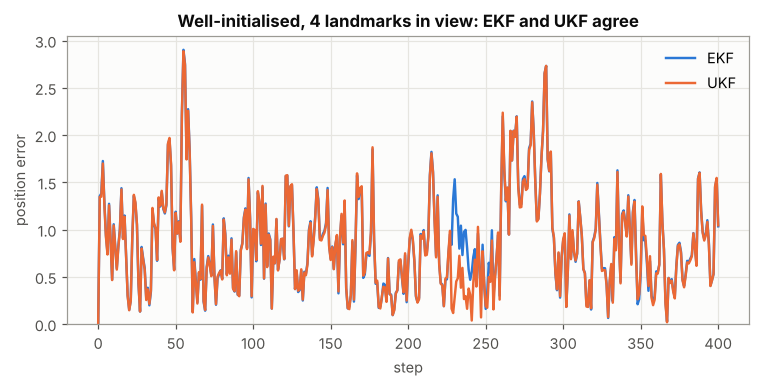

EKF: RMSE 1.008   time 0.12 ms/step
UKF: RMSE 0.991   time 0.18 ms/step


In [4]:
world = World.default()
run = simulate(world, n_steps=400, seed=1)
P0 = np.diag([10.0, 10.0, 0.05])
r_ekf = run_filter(EKF.from_world(world, run.truth[0], P0), run)
r_ukf = run_filter(UKF.from_world(world, run.truth[0], P0), run)

fig, ax = plt.subplots(figsize=(8, 3.4))
viz.plot_error_over_time(ax, [r_ekf, r_ukf], run.truth)
ax.set_title("Well-initialised, 4 landmarks in view: EKF and UKF agree")
plt.show()
for r in (r_ekf, r_ukf):
    print(f"{r.name}: RMSE {position_rmse(r.means, run.truth, skip=10):.3f}   time {r.seconds * 1000 / run.n_steps:.2f} ms/step")

When the uncertainty is small compared to the curvature of $f$ and $h$, linearisation is
excellent and the two filters are indistinguishable. The UKF needs 11 + 7 model evaluations
and two Cholesky factorisations per step instead of two Jacobians. Vectorised as here, that
costs only about 30% more time.

## 3. Where the UKF earns its keep

The uncertain-start experiment of notebook 03, now with both filters on exactly the same runs
and initial estimates:

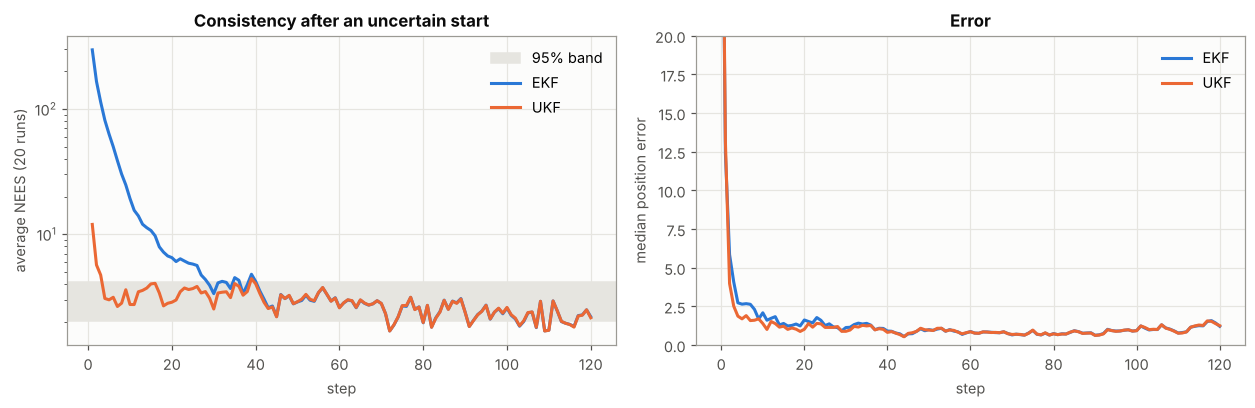

EKF: average NEES at steps 1, 5, 20 =  297.0   63.1   6.5
UKF: average NEES at steps 1, 5, 20 =   12.0    3.0   2.9


In [5]:
world_lr = World.default(max_range=110)
P0 = np.diag([30.0**2, 30.0**2, 0.8**2])
N, T = 20, 120
out = {"EKF": ([], []), "UKF": ([], [])}
for k in range(N):
    r = simulate(world_lr, n_steps=T, seed=k)
    x0 = r.truth[0] + np.random.default_rng(100 + k).multivariate_normal(np.zeros(3), P0)
    for cls in (EKF, UKF):
        rr = run_filter(cls.from_world(world_lr, x0, P0), r)
        out[cls.name][0].append(nees(rr.means, rr.covs, r.truth))
        out[cls.name][1].append(position_error(rr.means, r.truth))
lo, hi = nees_bounds(3, N)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.8))
a1.axhspan(lo, hi, color=viz.GRID, label="95% band")
for name, (ne, er) in out.items():
    ne, er = np.array(ne), np.array(er)
    a1.plot(np.arange(1, T + 1), ne.mean(0)[1:], color=viz.color(name), label=name)
    a2.plot(np.median(er, 0), color=viz.color(name), label=name)
a1.set_yscale("log"); a1.set_xlabel("step"); a1.set_ylabel("average NEES (20 runs)"); a1.legend()
a1.set_title("Consistency after an uncertain start")
a2.set_ylim(0, 20); a2.set_xlabel("step"); a2.set_ylabel("median position error"); a2.legend()
a2.set_title("Error")
plt.tight_layout(); plt.show()
for name, (ne, er) in out.items():
    ne = np.array(ne)
    print(f"{name}: average NEES at steps 1, 5, 20 = {ne[:, 1].mean():6.1f} {ne[:, 5].mean():6.1f} {ne[:, 20].mean():5.1f}")

The UKF is close to consistent from the first update, while the EKF is over-confident by
two orders of magnitude. The UKF's error also drops slightly faster. This is the regime the UKF is
for: **large uncertainty relative to the non-linearity**. Once both have converged they are
the same filter again.